In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
sns.set_theme(style="whitegrid")

In [21]:
pd.set_option('display.max_columns', None)

In [22]:
customer_demographics = pd.read_csv('/content/drive/MyDrive/MMLA Datasets/Cleaned Dataset/Customer_Demographics_Cleaned_Dataset.csv')
customer_transactions = pd.read_csv('/content/drive/MyDrive/MMLA Datasets/Cleaned Dataset/Customer_Transaction_Cleaned_Dataset.csv')
social_media_interactions = pd.read_csv('/content/drive/MyDrive/MMLA Datasets/Cleaned Dataset/Social_Media_Interactions_Cleaned_Dataset.csv')

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
datasets = {
    "Customer Demographics": customer_demographics,
    "Customer Transactions": customer_transactions,
    "Social Media Interactions": social_media_interactions
}

In [25]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name)
    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isna().sum().sum())
    print("\nData types:")
    print(df.dtypes)
    display(df.head())


Customer Demographics
Shape: (3023, 6)
Duplicate rows: 0
Missing values: 0

Data types:
CustomerID      object
Age            float64
Gender          object
Location        object
IncomeLevel     object
SignupDate      object
dtype: object


,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
0,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,Female,Jensenberg,Low,2022-11-17
1,5fb09cd8-a473-46f7-80bd-6e49cf509078,45.0,Female,Castilloport,High,2020-07-21
2,c139496e-cc89-498a-bd90-1fb4627b6cff,37.0,Male,Lake Jennifertown,Undetermined,2021-01-01
3,50118139-7264-428f-81cc-a25fddc5d6dd,44.0,Male,Port Carl,Medium,2024-06-10
4,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50.0,Female,Jessebury,High,2023-08-24



Customer Transactions
Shape: (3015, 6)
Duplicate rows: 0
Missing values: 0

Data types:
CustomerID          object
TransactionID       object
TransactionDate     object
Amount             float64
ProductCategory     object
PaymentMethod       object
dtype: object


,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod
0,60567026-f719-4cd6-849e-137e86d8938f,5ff75116-0a50-4d04-80fb-31e5ccbb0769,2024-05-15,117.64,Clothing,PayPal
1,4090ba85-b111-4f75-a792-c777965f5255,2c39b9fe-ff57-4d39-9321-9f5cdf187aa1,2023-04-26,466.14,Health & Beauty,Bank Transfer
2,9223891b-73ff-4d5c-b8ae-13ece82ee28b,f79588dd-3db9-4ffa-97f8-7de0e64259f1,2022-09-23,563.99,Clothing,Debit Card
3,9243eebc-938f-480c-8564-16d503d250de,401c0fc9-60df-4455-ad78-67c132f9897d,2024-04-15,254.44,Automotive,PayPal
4,6e3e8eb8-bc0f-4ffe-9f74-5d5efec9502f,2034aebc-8280-4254-a667-92bcd1c2be4f,2024-06-03,590.52,Home & Garden,Bank Transfer



Social Media Interactions
Shape: (3020, 6)
Duplicate rows: 0
Missing values: 0

Data types:
CustomerID         object
InteractionID      object
InteractionDate    object
Platform           object
InteractionType    object
Sentiment          object
dtype: object


,CustomerID,InteractionID,InteractionDate,Platform,InteractionType,Sentiment
0,2dcb9523-356b-40b2-a67b-1f27797de261,e5d15761-d0a7-4329-89e3-79a892c56097,2023-07-11,Undetermined,Comment,Undetermined
1,e12c37b3-7d4d-472f-9fd8-0df2cb3001aa,02f9f376-70ae-4fcd-9070-1db977939948,2023-07-06,Twitter,Share,Undetermined
2,08a911a3-65e6-4f5d-a6a1-ae7ddcbe28a2,a83fa04c-f109-4f24-8ce1-2078154f6a1c,2024-05-24,Instagram,Comment,Neutral
3,efdfdfc9-5dbb-4478-911a-101a390a0285,28a69c4b-a2e4-4c74-a130-1132d7733fdf,2023-11-01,Instagram,Like,Neutral
4,ca1e90f6-0e5f-492e-ab92-252ff540da18,d9d1c6f8-5e15-4738-b52b-13c2982420cc,2023-07-08,Instagram,Like,Undetermined


In [26]:
age = customer_demographics["Age"].dropna().to_numpy()
amount = customer_transactions["Amount"].dropna().to_numpy()

def calculate_statistics(data, variable_name):
    print(f"\n{'=' * 45}")
    print(f"{variable_name} Statistics")
    print(f"{'=' * 45}")
    print(f"Count: {np.size(data)}")
    print(f"Mean: {np.mean(data):.2f}")
    print(f"Median: {np.median(data):.2f}")
    print(f"Standard Deviation: {np.std(data):.2f}")
    print(f"Variance: {np.var(data):.2f}")
    print(f"Minimum: {np.min(data):.2f}")
    print(f"Maximum: {np.max(data):.2f}")
    print(f"Range: {np.ptp(data):.2f}")

calculate_statistics(age, "Customer Age")
calculate_statistics(amount, "Transaction Amount")



Customer Age Statistics
Count: 3023
Mean: 44.69
Median: 45.00
Standard Deviation: 14.42
Variance: 207.98
Minimum: 18.00
Maximum: 70.00
Range: 52.00

Transaction Amount Statistics
Count: 3015
Mean: 493.62
Median: 498.01
Standard Deviation: 279.25
Variance: 77983.20
Minimum: 0.00
Maximum: 999.86
Range: 999.86


In [27]:
def analyze_distribution(data, variable_name):
    q1 = np.percentile(data, 25)
    q2 = np.percentile(data, 50)
    q3 = np.percentile(data, 75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    potential_outliers = data[
        (data < lower_bound) | (data > upper_bound)
    ]

    print(f"\n{'=' * 45}")
    print(f"{variable_name} Distribution Analysis")
    print(f"{'=' * 45}")
    print(f"25th percentile (Q1): {q1:.2f}")
    print(f"Median (Q2): {q2:.2f}")
    print(f"75th percentile (Q3): {q3:.2f}")
    print(f"Interquartile range (IQR): {iqr:.2f}")
    print(f"Lower outlier boundary: {lower_bound:.2f}")
    print(f"Upper outlier boundary: {upper_bound:.2f}")
    print(f"Potential outlier count: {len(potential_outliers)}")

analyze_distribution(age, "Customer Age")
analyze_distribution(amount, "Transaction Amount")


Customer Age Distribution Analysis
25th percentile (Q1): 34.00
Median (Q2): 45.00
75th percentile (Q3): 57.00
Interquartile range (IQR): 23.00
Lower outlier boundary: -0.50
Upper outlier boundary: 91.50
Potential outlier count: 0

Transaction Amount Distribution Analysis
25th percentile (Q1): 257.31
Median (Q2): 498.01
75th percentile (Q3): 720.39
Interquartile range (IQR): 463.08
Lower outlier boundary: -437.31
Upper outlier boundary: 1415.01
Potential outlier count: 0


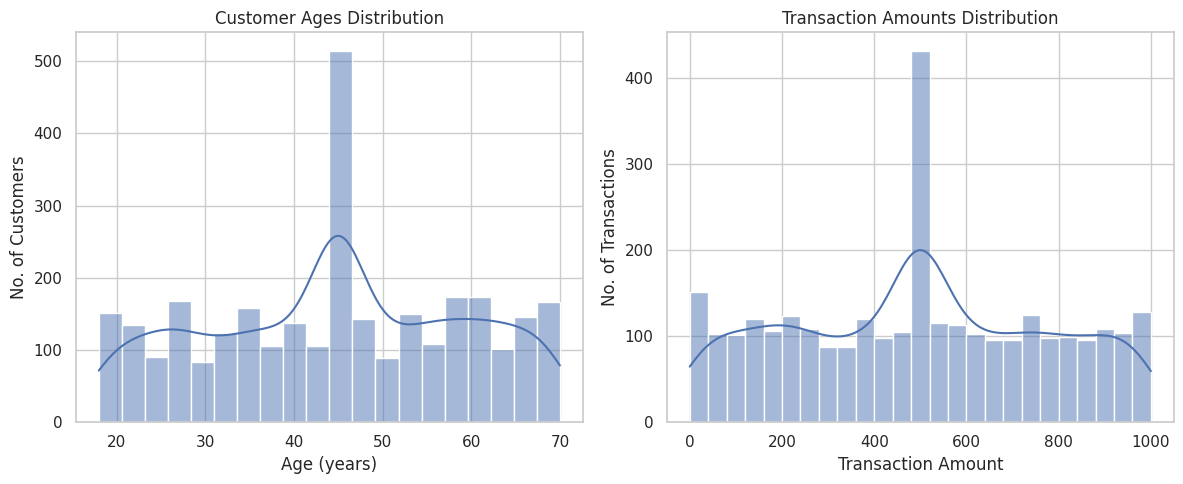

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=customer_demographics,
    x="Age",
    bins=20,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Customer Ages Distribution")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("No. of Customers")

sns.histplot(
    data=customer_transactions,
    x="Amount",
    bins=25,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Transaction Amounts Distribution")
axes[1].set_xlabel("Transaction Amount")
axes[1].set_ylabel("No. of Transactions")

plt.tight_layout()
plt.show()


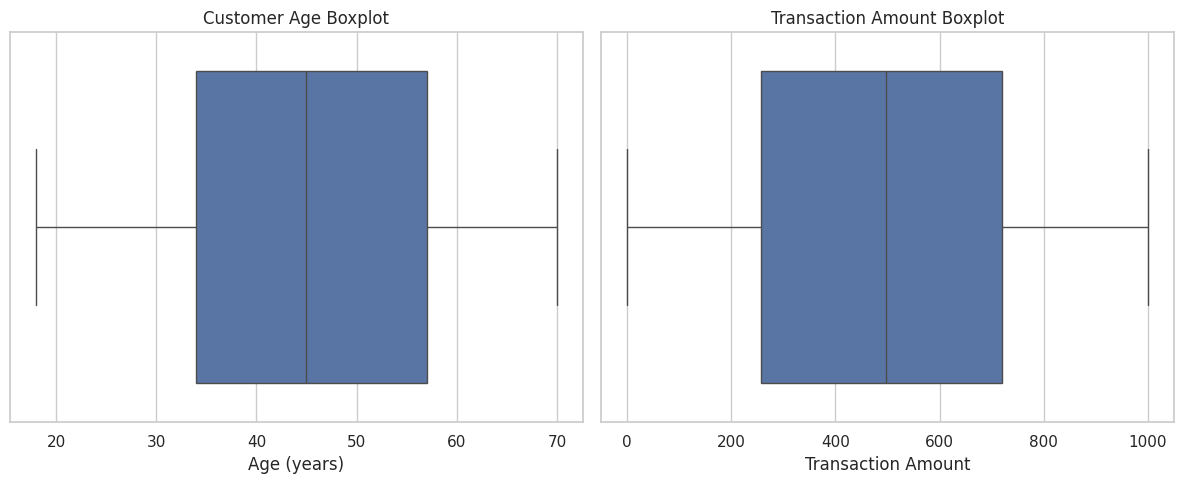

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=customer_demographics, x="Age", ax=axes[0])
axes[0].set_title("Customer Age Boxplot")
axes[0].set_xlabel("Age (years)")

sns.boxplot(data=customer_transactions, x="Amount", ax=axes[1])
axes[1].set_title("Transaction Amount Boxplot")
axes[1].set_xlabel("Transaction Amount")

plt.tight_layout()
plt.show()

In [30]:
zero_transactions = customer_transactions[
    customer_transactions["Amount"] == 0
].copy()

zero_count = len(zero_transactions)
total_transactions = len(customer_transactions)
zero_percentage = (zero_count / total_transactions) * 100

print("Zero-value transactions:", zero_count)
print(f"Percentage of all transactions: {zero_percentage:.2f}%")

print("\nZero-value transactions by product category:")
display(
    zero_transactions["ProductCategory"]
    .value_counts()
    .rename_axis("Product Category")
    .reset_index(name="Transaction Count")
)

print("\nZero-value transactions by payment method:")
display(
    zero_transactions["PaymentMethod"]
    .value_counts()
    .rename_axis("Payment Method")
    .reset_index(name="Transaction Count")
)

Zero-value transactions: 60
Percentage of all transactions: 1.99%

Zero-value transactions by product category:


,Product Category,Transaction Count
0,Home & Garden,14
1,Clothing,13
2,Electronics,12
3,Health & Beauty,11
4,Automotive,7
5,Undetermined,3



Zero-value transactions by payment method:


,Payment Method,Transaction Count
0,PayPal,18
1,Credit Card,17
2,Debit Card,16
3,Bank Transfer,9


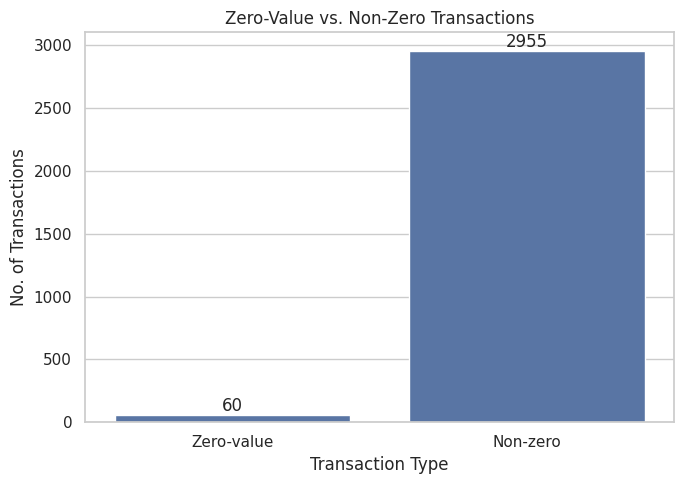

In [31]:
customer_transactions["Transaction Value Type"] = np.where(
    customer_transactions["Amount"] == 0,
    "Zero-value",
    "Non-zero"
)

value_type_counts = (
    customer_transactions["Transaction Value Type"]
    .value_counts()
    .reindex(["Zero-value", "Non-zero"], fill_value=0)
)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=value_type_counts.index,
    y=value_type_counts.values
)

ax.set_title("Zero-Value vs. Non-Zero Transactions")
ax.set_xlabel("Transaction Type")
ax.set_ylabel("No. of Transactions")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()


In [32]:
customer_spending = (
    customer_transactions
    .groupby("CustomerID", as_index=False)
    .agg(
        AverageTransactionAmount=("Amount", "mean"),
        TransactionCount=("TransactionID", "nunique")
    )
)

print("Unique customers with transactions:", len(customer_spending))
display(customer_spending.head())

Unique customers with transactions: 1871


,CustomerID,AverageTransactionAmount,TransactionCount
0,0009fdd2-ae63-45ca-8d5b-d0ea98381f7b,389.690,1
1,00115fc0-f155-42cd-ba68-58aab67b3360,222.740,2
2,0047d8ce-a5bb-4db7-860f-6ff66e1cd060,259.470,1
3,0064a8b2-71d3-41c1-a46a-6eea56fdff91,688.785,4
4,00742b15-bab0-440f-a085-221ce13d95a0,323.010,2


In [33]:
age_spending = customer_demographics[
    ["CustomerID", "Age"]
].merge(
    customer_spending,
    on="CustomerID",
    how="inner",
    validate="many_to_one"
)

print("Matched demographic records:", len(age_spending))
print("Unique matched customers:", age_spending["CustomerID"].nunique())

display(age_spending.head())

Matched demographic records: 1889
Unique matched customers: 1871


,CustomerID,Age,AverageTransactionAmount,TransactionCount
0,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,579.442500,2
1,5fb09cd8-a473-46f7-80bd-6e49cf509078,45.0,976.880000,1
2,c139496e-cc89-498a-bd90-1fb4627b6cff,37.0,528.320000,1
3,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50.0,733.460000,1
4,2de49c7c-32ae-4ba8-b058-622a090d7094,53.0,297.246667,3


In [34]:
duplicate_customer_ids = customer_demographics[
    customer_demographics.duplicated(
        subset="CustomerID",
        keep=False
    )].sort_values("CustomerID")

print(
    "Unique CustomerIDs in demographics:",
    customer_demographics["CustomerID"].nunique()
)

print(
    "Rows involved in repeated CustomerIDs:",
    len(duplicate_customer_ids)
)

print(
    "Number of repeated CustomerIDs:",
    duplicate_customer_ids["CustomerID"].nunique()
)

display(duplicate_customer_ids.head(10))

Unique CustomerIDs in demographics: 3000
Rows involved in repeated CustomerIDs: 46
Number of repeated CustomerIDs: 23


,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
3001,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,2020-03-28
1536,08995799-8d0f-40d6-986b-452074709b5f,61.0,Male,New Lukeville,Medium,2019-11-15
3009,1e9e7dcb-e612-46d3-bae6-0c2f47fa0220,44.0,Female,Brianmouth,Medium,2019-11-07
304,1e9e7dcb-e612-46d3-bae6-0c2f47fa0220,44.0,Female,Brianmouth,Medium,2022-07-28
3008,29436bcf-d6f8-44d1-a856-0794abb562ab,68.0,Female,New Fred,Low,2020-03-12
754,29436bcf-d6f8-44d1-a856-0794abb562ab,68.0,Female,New Fred,Low,2021-09-01
3004,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,52.0,Female,Lake Carloshaven,Medium,2024-05-02
2106,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,45.0,Female,Lake Carloshaven,Medium,2024-05-02
1238,3814b8e4-cade-4665-86af-dda3e3628f17,32.0,Female,Port Bonnieshire,Medium,2021-06-25
3000,3814b8e4-cade-4665-86af-dda3e3628f17,45.0,Female,Port Bonnieshire,Medium,2021-06-25


In [35]:
age_variation = (
    customer_demographics
    .groupby("CustomerID")["Age"]
    .nunique()
)

print(
    "CustomerIDs with multiple distinct ages:",
    (age_variation > 1).sum()
)

print(
    "CustomerIDs with only one distinct age:",
    (age_variation <= 1).sum()
)

CustomerIDs with multiple distinct ages: 11
CustomerIDs with only one distinct age: 2989


In [36]:
conflicting_age_ids = age_variation[age_variation > 1].index

conflicting_age_records = (
    customer_demographics[
        customer_demographics["CustomerID"].isin(conflicting_age_ids)
    ]
    .sort_values(["CustomerID", "Age"])
)

print("Number of customers with conflicting ages:", len(conflicting_age_ids))
display(conflicting_age_records)

Number of customers with conflicting ages: 11


,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
2106,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,45.0,Female,Lake Carloshaven,Medium,2024-05-02
3004,2cd16dfc-d7b0-47ec-9999-b018daea7f8d,52.0,Female,Lake Carloshaven,Medium,2024-05-02
1238,3814b8e4-cade-4665-86af-dda3e3628f17,32.0,Female,Port Bonnieshire,Medium,2021-06-25
3000,3814b8e4-cade-4665-86af-dda3e3628f17,45.0,Female,Port Bonnieshire,Medium,2021-06-25
338,48313b18-ccdb-4946-b958-1ebfc92dcc2a,45.0,Male,South Andrea,High,2020-02-26
3018,48313b18-ccdb-4946-b958-1ebfc92dcc2a,59.0,Male,South Andrea,High,2020-02-26
3002,50465bde-6a9a-466d-804a-a8f046809a23,35.0,Male,Harrismouth,High,2023-08-02
539,50465bde-6a9a-466d-804a-a8f046809a23,45.0,Male,Harrismouth,High,2023-08-02
3014,5050eefe-2392-4d18-b4b6-913d42b9f62b,20.0,Female,Alexanderstad,High,2021-02-20
1768,5050eefe-2392-4d18-b4b6-913d42b9f62b,45.0,Female,Alexanderstad,High,2021-02-20


In [37]:
age_counts = customer_demographics.groupby("CustomerID")["Age"].nunique()
conflicting_age_ids = age_counts[age_counts > 1].index

demographics_for_analysis = customer_demographics[
    ~customer_demographics["CustomerID"].isin(conflicting_age_ids)
].copy()

demographics_for_analysis = demographics_for_analysis.drop_duplicates(
    subset="CustomerID"
)


age_spending_clean = demographics_for_analysis[
    ["CustomerID", "Age"]
].merge(
    customer_spending,
    on="CustomerID",
    how="inner",
    validate="one_to_one"
)


print("Customers with conflicting ages excluded:", len(conflicting_age_ids))
print("Customers in age-spending analysis:", len(age_spending_clean))
print("Duplicate CustomerIDs:", age_spending_clean["CustomerID"].duplicated().sum())

correlation = np.corrcoef(
    age_spending_clean["Age"],
    age_spending_clean["AverageTransactionAmount"]
)[0, 1]

print(f"Age vs. average transaction amount correlation: {correlation:.3f}")

Customers with conflicting ages excluded: 11
Customers in age-spending analysis: 1862
Duplicate CustomerIDs: 0
Age vs. average transaction amount correlation: 0.039


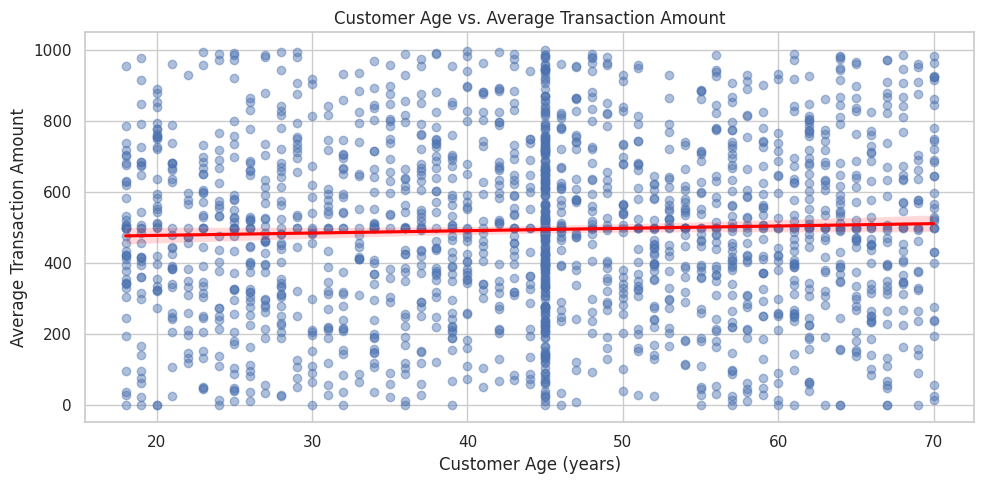

In [38]:
plt.figure(figsize=(10, 5))

sns.regplot(
    data=age_spending_clean,
    x="Age",
    y="AverageTransactionAmount",
    scatter_kws={"alpha": 0.45},
    line_kws={"color": "red"}
)

plt.title("Customer Age vs. Average Transaction Amount")
plt.xlabel("Customer Age (years)")
plt.ylabel("Average Transaction Amount")
plt.tight_layout()
plt.show()


In [39]:
customer_transactions["TransactionDate"] = pd.to_datetime(
    customer_transactions["TransactionDate"],
    errors="coerce"
)

monthly_transactions = (
    customer_transactions
    .dropna(subset=["TransactionDate"])
    .set_index("TransactionDate")
    .resample("MS")
    .agg(
        TransactionCount=("TransactionID", "nunique"),
        TotalTransactionAmount=("Amount", "sum"),
        AverageTransactionAmount=("Amount", "mean")
    )
    .reset_index()
)


print("Date range:")
print(monthly_transactions["TransactionDate"].min())
print("to", monthly_transactions["TransactionDate"].max())

print("\nMonthly transaction summary:")
display(monthly_transactions.head(10))

Date range:
2022-07-01 00:00:00
to 2024-06-01 00:00:00

Monthly transaction summary:


,TransactionDate,TransactionCount,TotalTransactionAmount,AverageTransactionAmount
0,2022-07-01,118,59057.815,496.284160
1,2022-08-01,112,52833.665,467.554558
2,2022-09-01,120,56059.070,467.158917
3,2022-10-01,119,59902.895,503.385672
4,2022-11-01,126,59838.395,474.907897
5,2022-12-01,135,71285.825,528.043148
6,2023-01-01,119,54194.960,455.419832
7,2023-02-01,110,51153.780,465.034364
8,2023-03-01,135,69763.430,516.766148
9,2023-04-01,116,54251.025,467.681250


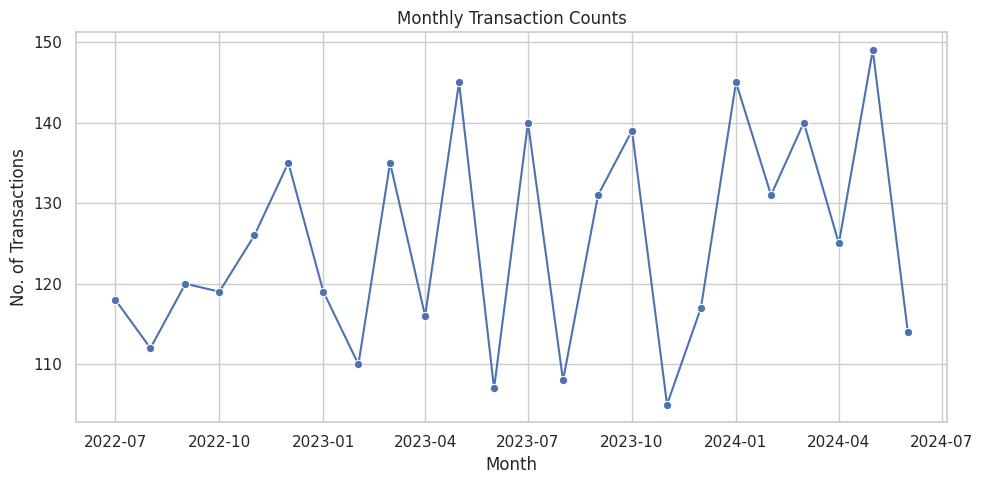

In [40]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_transactions,
    x="TransactionDate",
    y="TransactionCount",
    marker="o"
)

plt.title("Monthly Transaction Counts")
plt.xlabel("Month")
plt.ylabel("No. of Transactions")
plt.tight_layout()
plt.show()

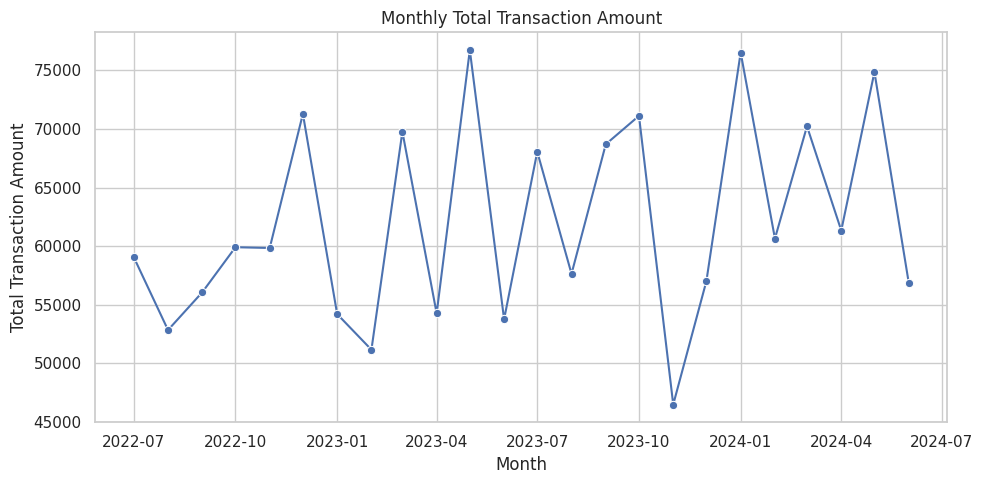

In [41]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_transactions,
    x="TransactionDate",
    y="TotalTransactionAmount",
    marker="o"
)

plt.title("Monthly Total Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Total Transaction Amount")
plt.tight_layout()
plt.show()

In [42]:
social_media_interactions["InteractionDate"] = pd.to_datetime(
    social_media_interactions["InteractionDate"],
    errors="coerce"
)

monthly_social = (
    social_media_interactions
    .dropna(subset=["InteractionDate"])
    .set_index("InteractionDate")
    .resample("MS")
    .agg(
        InteractionCount=("InteractionID", "nunique")
    )
    .reset_index()
)

print("Social media date range:")
print(monthly_social["InteractionDate"].min())
print("to", monthly_social["InteractionDate"].max())

print("\nMonthly social media summary:")
display(monthly_social)

Social media date range:
2023-07-01 00:00:00
to 2024-06-01 00:00:00

Monthly social media summary:


,InteractionDate,InteractionCount
0,2023-07-01,272
1,2023-08-01,241
2,2023-09-01,242
3,2023-10-01,265
4,2023-11-01,232
5,2023-12-01,258
6,2024-01-01,258
7,2024-02-01,237
8,2024-03-01,251
9,2024-04-01,253


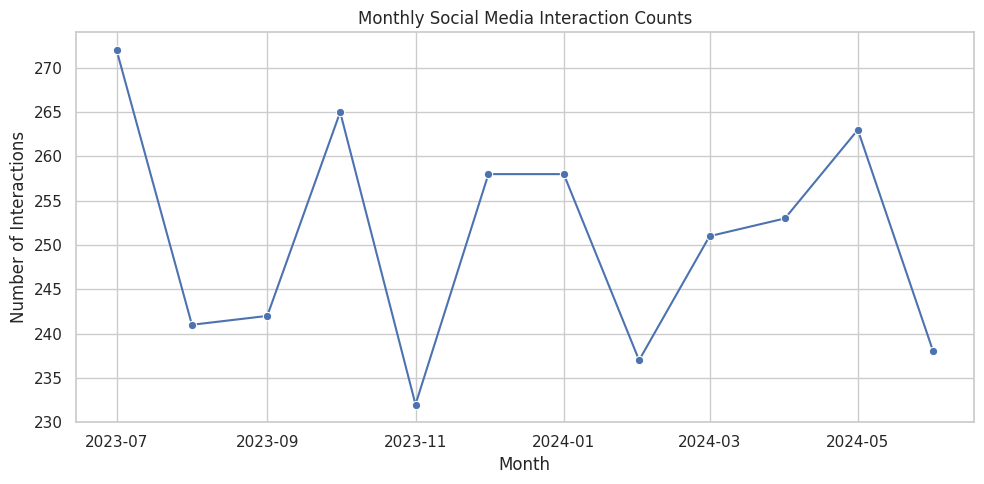

In [43]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_social,
    x="InteractionDate",
    y="InteractionCount",
    marker="o"
)

plt.title("Monthly Social Media Interaction Counts")
plt.xlabel("Month")
plt.ylabel("Number of Interactions")
plt.tight_layout()
plt.show()

In [44]:
transactions_comparison = monthly_transactions[
    (monthly_transactions["TransactionDate"] >= "2023-07-01") &
    (monthly_transactions["TransactionDate"] <= "2024-06-30")
].copy()

monthly_comparison = transactions_comparison.merge(
    monthly_social,
    left_on="TransactionDate",
    right_on="InteractionDate",
    how="inner",
    validate="one_to_one"
)

monthly_comparison = monthly_comparison.drop(
    columns=["InteractionDate"]
)

display(monthly_comparison)

,TransactionDate,TransactionCount,TotalTransactionAmount,AverageTransactionAmount,InteractionCount
0,2023-07-01,140,68052.500,486.089286,272
1,2023-08-01,108,57632.700,533.636111,241
2,2023-09-01,131,68693.110,516.489549,242
3,2023-10-01,139,71117.020,507.978714,265
4,2023-11-01,105,46475.220,442.621143,232
5,2023-12-01,117,57009.760,483.133559,258
6,2024-01-01,145,76522.000,527.737931,258
7,2024-02-01,131,60646.565,462.950878,237
8,2024-03-01,140,70222.585,501.589893,251
9,2024-04-01,125,61330.090,490.640720,253


In [45]:
monthly_correlation = monthly_comparison[
    ["TransactionCount", "InteractionCount"]
].corr().iloc[0, 1]

print(
    "Correlation between monthly transaction count "
    "and social media interactions:",
    round(monthly_correlation, 3)
)

Correlation between monthly transaction count and social media interactions: 0.696


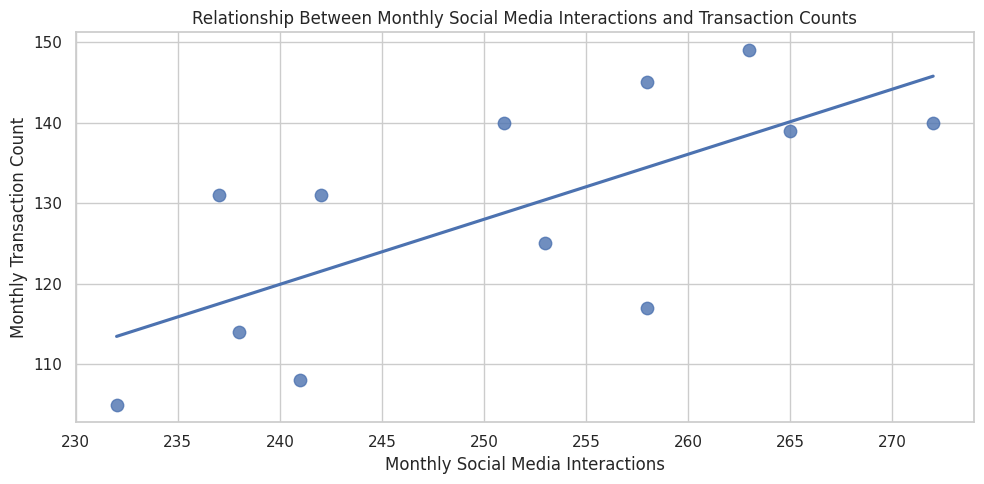

In [46]:
plt.figure(figsize=(10, 5))

sns.regplot(
    data=monthly_comparison,
    x="InteractionCount",
    y="TransactionCount",
    ci=None,
    scatter_kws={"s": 80}
)

plt.title(
    "Relationship Between Monthly Social Media Interactions and Transaction Counts"
)
plt.xlabel("Monthly Social Media Interactions")
plt.ylabel("Monthly Transaction Count")
plt.tight_layout()
plt.show()

In [47]:
print("Sentiment distribution:")
display(
    social_media_interactions["Sentiment"]
    .value_counts(dropna=False)
    .rename_axis("Sentiment")
    .reset_index(name="InteractionCount")
)

print("\nSentiment by platform:")
display(
    pd.crosstab(
        social_media_interactions["Platform"],
        social_media_interactions["Sentiment"],
        margins=True
    )
)

Sentiment distribution:


,Sentiment,InteractionCount
0,Positive,905
1,Neutral,874
2,Negative,866
3,Undetermined,309
4,Very Negative,34
5,Very Positive,32



Sentiment by platform:


Sentiment,Negative,Neutral,Positive,Undetermined,Very Negative,Very Positive,All
Platform,,,,,,,
Facebook,246,262,269,94,14,6,891
Instagram,271,259,290,85,5,11,921
Twitter,272,276,245,103,9,12,917
Undetermined,77,77,101,27,6,3,291
All,866,874,905,309,34,32,3020


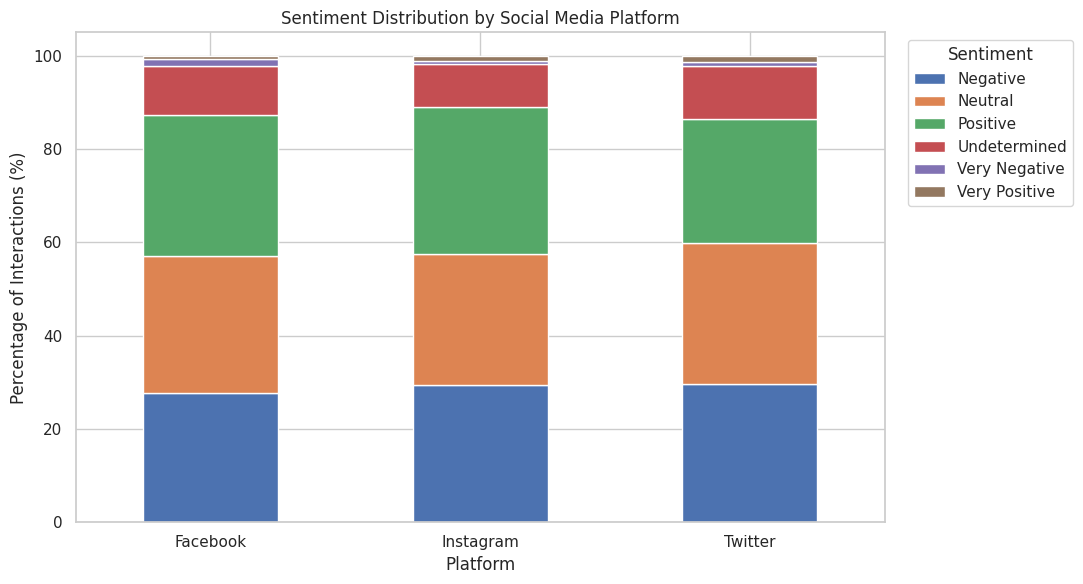

In [48]:
platform_sentiment = pd.crosstab(
    social_media_interactions["Platform"],
    social_media_interactions["Sentiment"]
)


named_platforms = platform_sentiment.drop(
    index="Undetermined",
    errors="ignore"
)


platform_sentiment_pct = (
    named_platforms
    .div(named_platforms.sum(axis=1), axis=0)
    * 100
)

platform_sentiment_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Sentiment Distribution by Social Media Platform")
plt.xlabel("Platform")
plt.ylabel("Percentage of Interactions (%)")
plt.xticks(rotation=0)
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [49]:
platform_totals = named_platforms.sum(axis=1)

platform_sentiment_rates = (
    named_platforms
    .assign(
        Total=platform_totals,
        PositiveRate=named_platforms["Positive"] / platform_totals * 100,
        NegativeRate=named_platforms["Negative"] / platform_totals * 100
    )
    .reset_index()
)

display(
    platform_sentiment_rates[
        ["Platform", "Total", "PositiveRate", "NegativeRate"]
    ].round(2)
)

Sentiment,Platform,Total,PositiveRate,NegativeRate
0,Facebook,891,30.19,27.61
1,Instagram,921,31.49,29.42
2,Twitter,917,26.72,29.66


In [50]:
print("Interaction type distribution:")
display(
    social_media_interactions["InteractionType"]
    .value_counts(dropna=False)
    .rename_axis("InteractionType")
    .reset_index(name="InteractionCount")
)

print("\nInteraction type by platform:")
display(
    pd.crosstab(
        social_media_interactions["Platform"],
        social_media_interactions["InteractionType"],
        margins=True
    )
)

Interaction type distribution:


,InteractionType,InteractionCount
0,Comment,1018
1,Share,1007
2,Like,995



Interaction type by platform:


InteractionType,Comment,Like,Share,All
Platform,,,,
Facebook,284,300,307,891
Instagram,307,317,297,921
Twitter,322,280,315,917
Undetermined,105,98,88,291
All,1018,995,1007,3020


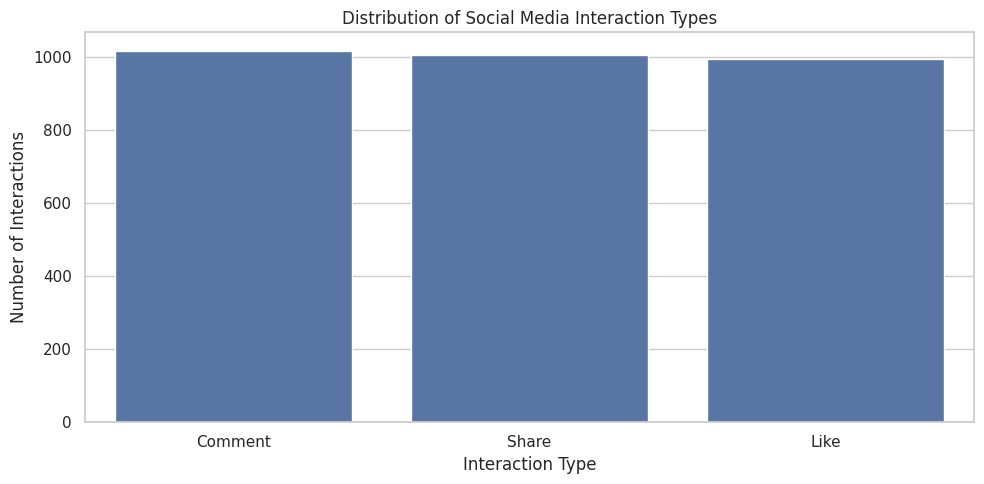

In [51]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=social_media_interactions,
    x="InteractionType",
    order=["Comment", "Share", "Like"]
)

plt.title("Distribution of Social Media Interaction Types")
plt.xlabel("Interaction Type")
plt.ylabel("Number of Interactions")
plt.tight_layout()
plt.show()

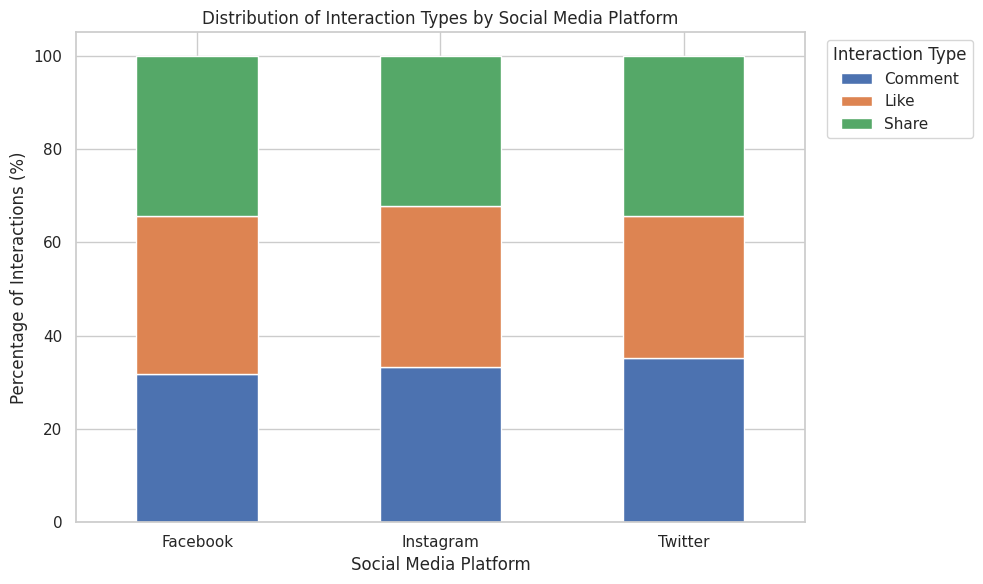

In [52]:
platform_interaction = pd.crosstab(
    social_media_interactions["Platform"],
    social_media_interactions["InteractionType"]
)

named_platform_interaction = platform_interaction.drop(
    index="Undetermined",
    errors="ignore"
)

platform_interaction_pct = (
    named_platform_interaction
    .div(named_platform_interaction.sum(axis=1), axis=0)
    * 100
)

platform_interaction_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Distribution of Interaction Types by Social Media Platform")
plt.xlabel("Social Media Platform")
plt.ylabel("Percentage of Interactions (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Interaction Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [53]:
sentiment_by_interaction = pd.crosstab(
    social_media_interactions["InteractionType"],
    social_media_interactions["Sentiment"]
)

display(sentiment_by_interaction)

Sentiment,Negative,Neutral,Positive,Undetermined,Very Negative,Very Positive
InteractionType,,,,,,
Comment,293,301,294,101,21,8
Like,289,289,302,101,3,11
Share,284,284,309,107,10,13


In [54]:
sentiment_by_interaction_pct = (
    sentiment_by_interaction
    .div(sentiment_by_interaction.sum(axis=1), axis=0)
    * 100
)

display(sentiment_by_interaction_pct.round(2))

Sentiment,Negative,Neutral,Positive,Undetermined,Very Negative,Very Positive
InteractionType,,,,,,
Comment,28.78,29.57,28.88,9.92,2.06,0.79
Like,29.05,29.05,30.35,10.15,0.30,1.11
Share,28.20,28.20,30.69,10.63,0.99,1.29


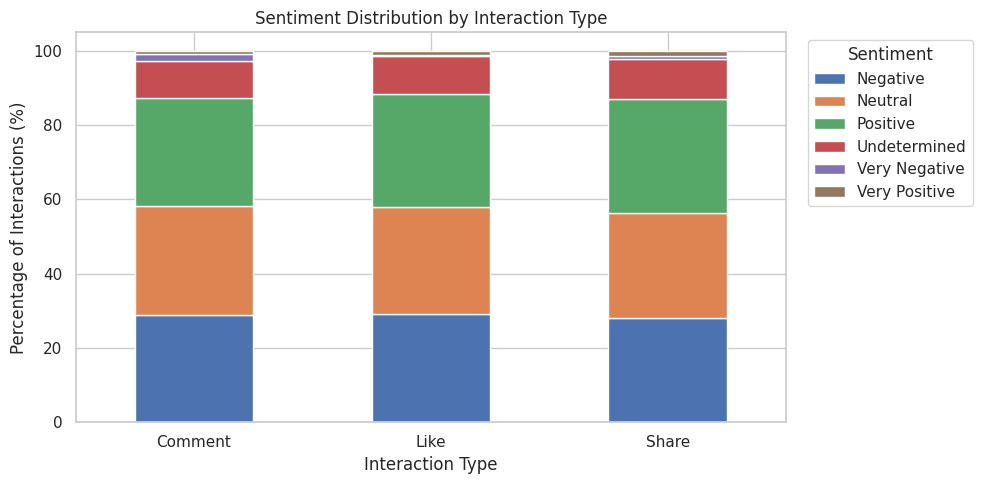

In [55]:
sentiment_by_interaction_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Sentiment Distribution by Interaction Type")
plt.xlabel("Interaction Type")
plt.ylabel("Percentage of Interactions (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [56]:
category_spending = (
    customer_transactions
    .groupby("ProductCategory", as_index=False)
    .agg(
        AverageAmount=("Amount", "mean"),
        TransactionCount=("TransactionID", "nunique"),
        TotalAmount=("Amount", "sum")
    )
    .sort_values("AverageAmount", ascending=False)
)

display(category_spending)

,ProductCategory,AverageAmount,TransactionCount,TotalAmount
4,Home & Garden,515.460962,529,273194.310
0,Automotive,500.234222,538,270126.480
1,Clothing,494.228117,568,282204.255
2,Electronics,487.447429,561,274920.350
5,Undetermined,479.671773,280,135267.440
3,Health & Beauty,478.325133,524,252555.670


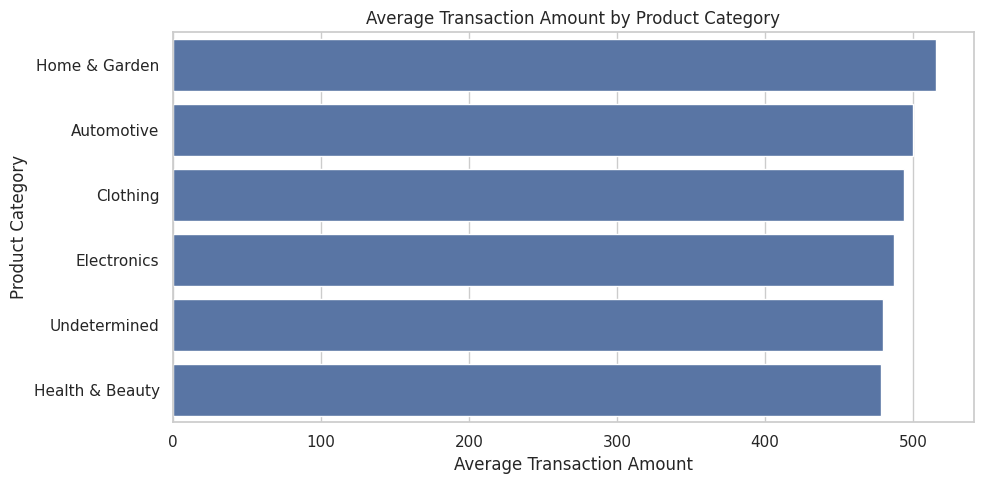

In [57]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_spending,
    x="AverageAmount",
    y="ProductCategory"
)

plt.title("Average Transaction Amount by Product Category")
plt.xlabel("Average Transaction Amount")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

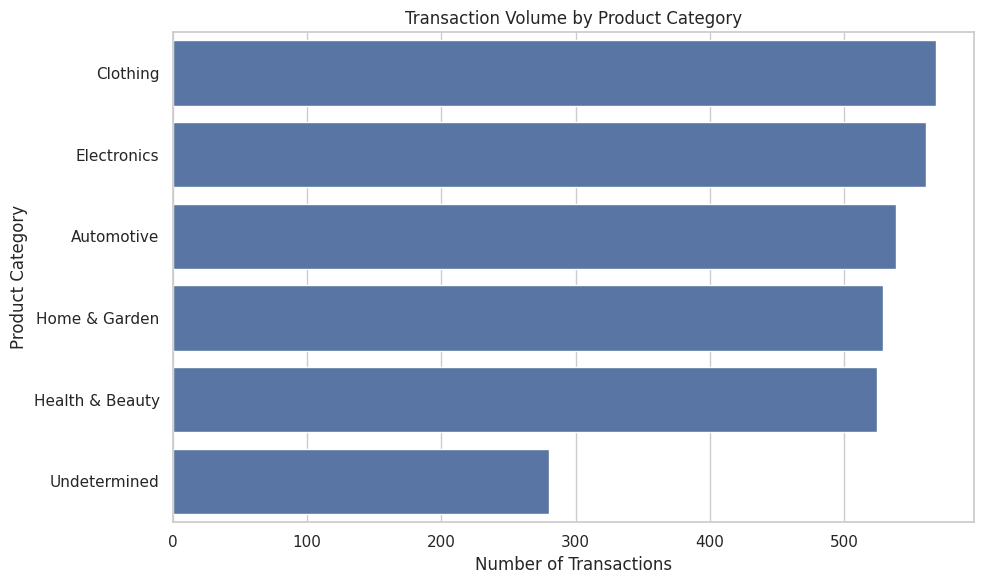

In [58]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_spending.sort_values("TransactionCount", ascending=False),
    x="TransactionCount",
    y="ProductCategory"
)

plt.title("Transaction Volume by Product Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [59]:
payment_analysis = (
    customer_transactions
    .groupby("PaymentMethod", as_index=False)
    .agg(
        AverageAmount=("Amount", "mean"),
        TransactionCount=("TransactionID", "nunique"),
        TotalAmount=("Amount", "sum")
    )
    .sort_values("AverageAmount", ascending=False)
)

display(payment_analysis)

,PaymentMethod,AverageAmount,TransactionCount,TotalAmount
1,Credit Card,499.865642,753,377398.560
3,PayPal,496.491027,747,372368.270
2,Debit Card,495.215756,762,379830.485
0,Bank Transfer,482.733769,738,358671.190


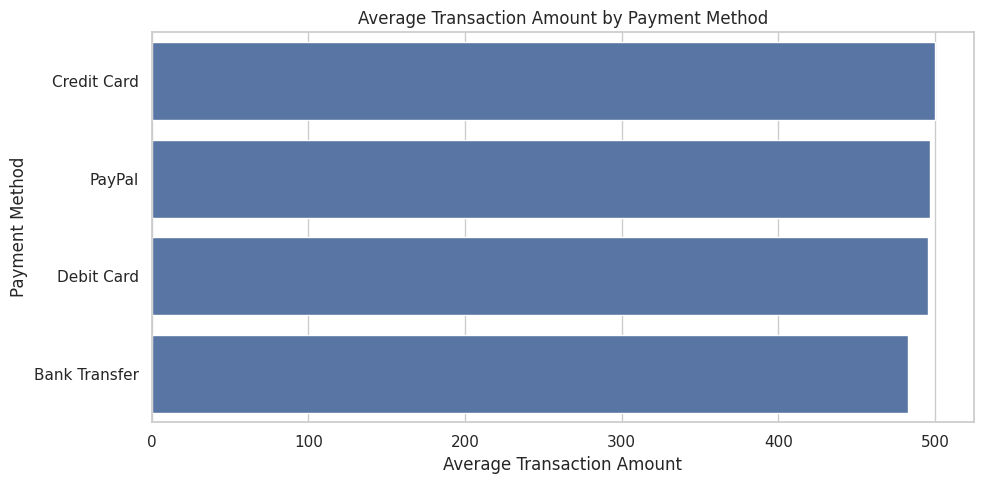

In [60]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_analysis,
    x="AverageAmount",
    y="PaymentMethod"
)

plt.title("Average Transaction Amount by Payment Method")
plt.xlabel("Average Transaction Amount")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

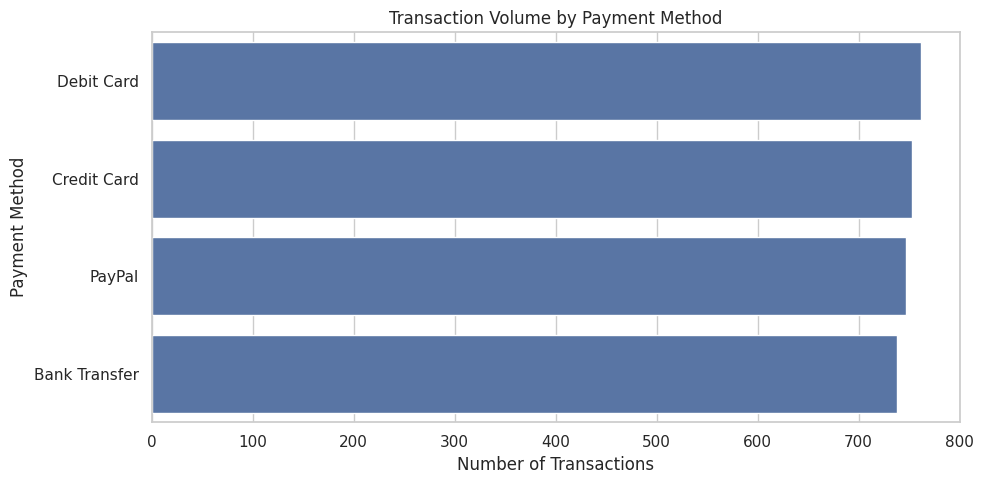

In [61]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_analysis.sort_values(
        "TransactionCount", ascending=False
    ),
    x="TransactionCount",
    y="PaymentMethod"
)

plt.title("Transaction Volume by Payment Method")
plt.xlabel("Number of Transactions")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

In [62]:
age_counts = customer_demographics.groupby("CustomerID")["Age"].nunique()

conflicting_age_ids = age_counts[age_counts > 1].index

demographics_for_analysis = customer_demographics[
    ~customer_demographics["CustomerID"].isin(conflicting_age_ids)
].copy()

demographics_for_analysis = demographics_for_analysis.drop_duplicates(
    subset="CustomerID"
)

demographics_for_analysis["AgeGroup"] = pd.cut(
    demographics_for_analysis["Age"],
    bins=[17, 25, 35, 45, 55, 65, 70],
    labels=[
        "18–25",
        "26–35",
        "36–45",
        "46–55",
        "56–65",
        "66–70"
    ],
    include_lowest=True
)

display(
    demographics_for_analysis["AgeGroup"]
    .value_counts()
    .sort_index()
)

,count
AgeGroup,
18–25,376
26–35,471
36–45,853
46–55,486
56–65,540
66–70,263


In [63]:
age_spending = demographics_for_analysis[
    ["CustomerID", "Age", "AgeGroup"]
].merge(
    customer_spending,
    on="CustomerID",
    how="inner",
    validate="one_to_one"
)

print("Customers included:", age_spending["CustomerID"].nunique())
print("Duplicate customer IDs:", age_spending["CustomerID"].duplicated().sum())

display(age_spending.head())

Customers included: 1862
Duplicate customer IDs: 0


,CustomerID,Age,AgeGroup,AverageTransactionAmount,TransactionCount
0,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,46–55,579.442500,2
1,5fb09cd8-a473-46f7-80bd-6e49cf509078,45.0,36–45,976.880000,1
2,c139496e-cc89-498a-bd90-1fb4627b6cff,37.0,36–45,528.320000,1
3,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50.0,46–55,733.460000,1
4,2de49c7c-32ae-4ba8-b058-622a090d7094,53.0,46–55,297.246667,3


In [64]:
age_group_analysis = (
    age_spending
    .groupby("AgeGroup", observed=False)
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        AverageTransactionAmount=("AverageTransactionAmount", "mean"),
        AverageTransactionCount=("TransactionCount", "mean")
    )
    .reset_index()
)

customer_totals = (
    customer_transactions
    .groupby("CustomerID", as_index=False)
    .agg(CustomerTotalAmount=("Amount", "sum"))
)

age_spending_totals = age_spending.merge(
    customer_totals,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

age_group_totals = (
    age_spending_totals
    .groupby("AgeGroup", observed=False)
    .agg(TotalTransactionAmount=("CustomerTotalAmount", "sum"))
    .reset_index()
)

age_group_analysis = age_group_analysis.merge(
    age_group_totals,
    on="AgeGroup",
    how="left",
    validate="one_to_one"
)

display(age_group_analysis.round(2))

,AgeGroup,CustomerCount,AverageTransactionAmount,AverageTransactionCount,TotalTransactionAmount
0,18–25,246,468.95,1.60,186982.42
1,26–35,280,474.15,1.58,211884.72
2,36–45,531,505.17,1.65,441515.30
3,46–55,307,506.15,1.64,253555.12
4,56–65,345,491.99,1.56,266612.52
5,66–70,153,504.15,1.50,117922.05


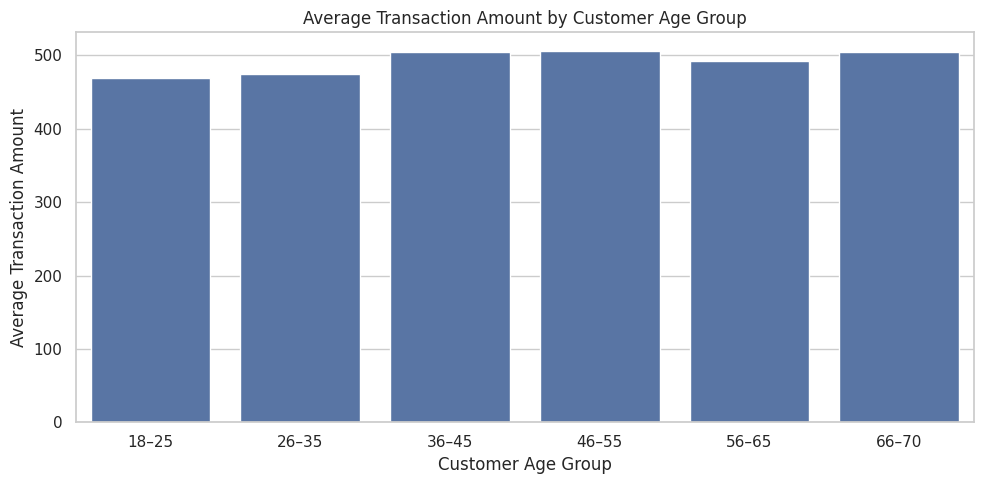

In [65]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_group_analysis,
    x="AgeGroup",
    y="AverageTransactionAmount"
)

plt.title("Average Transaction Amount by Customer Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Average Transaction Amount")
plt.tight_layout()
plt.show()

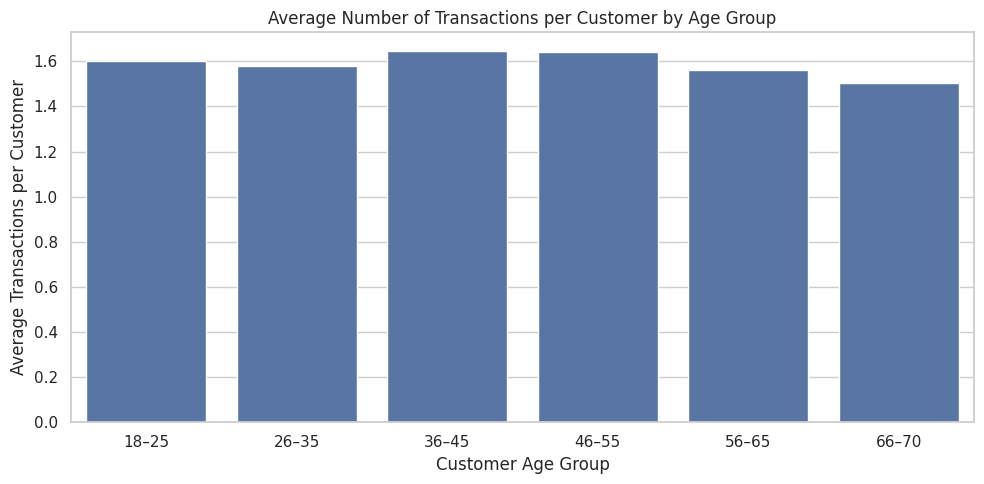

In [66]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_group_analysis,
    x="AgeGroup",
    y="AverageTransactionCount"
)

plt.title("Average Number of Transactions per Customer by Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Average Transactions per Customer")
plt.tight_layout()
plt.show()

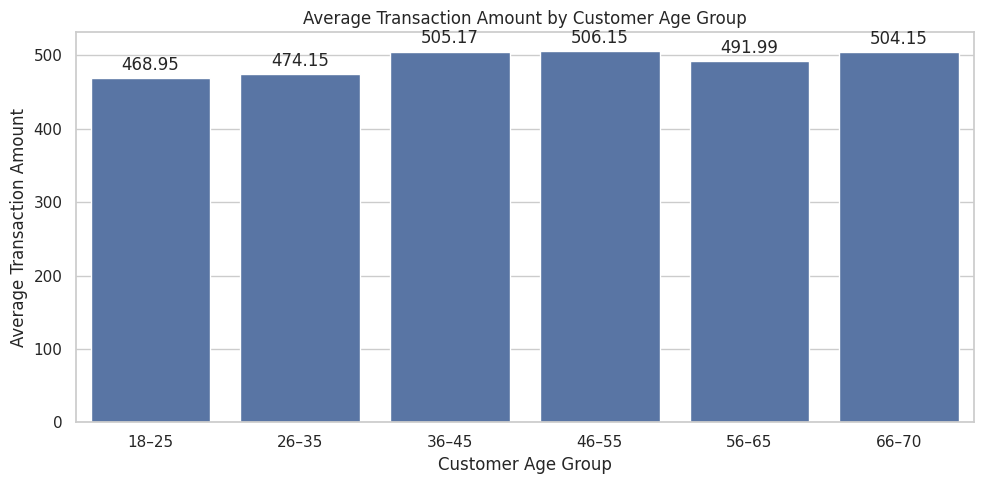

In [67]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=age_group_analysis,
    x="AgeGroup",
    y="AverageTransactionAmount"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Transaction Amount by Customer Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Average Transaction Amount")
plt.tight_layout()
plt.show()

In [68]:
print("Transaction rows:", len(customer_transactions))
print("Unique TransactionIDs:", customer_transactions["TransactionID"].nunique())
print("Rows sharing a TransactionID:", customer_transactions["TransactionID"].duplicated(keep=False).sum())

print("\nInteraction rows:", len(social_media_interactions))
print("Unique InteractionIDs:", social_media_interactions["InteractionID"].nunique())
print("Rows sharing an InteractionID:", social_media_interactions["InteractionID"].duplicated(keep=False).sum())

Transaction rows: 3015
Unique TransactionIDs: 3000
Rows sharing a TransactionID: 30

Interaction rows: 3020
Unique InteractionIDs: 3000
Rows sharing an InteractionID: 40
